# Task 5: Attention-Enhanced Conditional GAN — Oxford-102 Flowers

**Objective:** Improve the Conditional GAN from Task 2 by adding a **self-attention mechanism** so the network can model relationships between spatially separated image regions while generating category-conditioned flower visuals.

This notebook is a direct extension of the same **Oxford-102 Flowers** internship project and uses the same five representative categories as Task 2:

**daffodil, sunflower, rose, lotus, hibiscus**

### What this notebook demonstrates
- Reusing the Oxford-102 flower subset from Task 2
- Building a reusable Self-Attention layer
- Adding self-attention to both Generator and Discriminator
- Training an Attention-CGAN
- Visualizing attention-enhanced generated samples
- Plotting training losses
- Comparing the Task 5 architecture with the Task 2 baseline
- Saving models, generated images, and training history

> **Recommended runtime:** Google Colab GPU (`Runtime → Change runtime type → T4 GPU`).


## 1. Install and import libraries


In [1]:
!pip install -q scipy pillow matplotlib pandas tqdm


In [2]:
import os
import random
import tarfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.io
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.utils import make_grid, save_image

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)
if DEVICE.type != "cuda":
    print("Tip: Enable a T4 GPU in Colab for much faster training.")


Using device: cuda


## 2. Download the Oxford-102 Flowers dataset

The notebook uses the same official University of Oxford VGG image archive and label file as Task 4.


In [3]:
DATA_DIR = Path("flowers_data")
DATA_DIR.mkdir(exist_ok=True)

IMAGES_URL = "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/102flowers.tgz"
LABELS_URL = "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/imagelabels.mat"

images_tgz = DATA_DIR / "102flowers.tgz"
labels_path = DATA_DIR / "imagelabels.mat"
jpg_dir = DATA_DIR / "jpg"

if not images_tgz.exists():
    print("Downloading Oxford-102 images...")
    urllib.request.urlretrieve(IMAGES_URL, images_tgz)

if not labels_path.exists():
    print("Downloading labels...")
    urllib.request.urlretrieve(LABELS_URL, labels_path)

if not jpg_dir.exists():
    print("Extracting images...")
    with tarfile.open(images_tgz) as tar:
        tar.extractall(DATA_DIR)

print("Dataset ready:", jpg_dir)


Extracting images...


/tmp/ipykernel_3969/1807190630.py:22: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(DATA_DIR)


Dataset ready: flowers_data/jpg


## 3. Define class names and choose CGAN categories

Oxford-102 has 102 flower categories. A small CGAN trained in a normal Colab session is unlikely to learn all 102 classes well, so this **Task 2 experiment** uses five categories while remaining part of the same Oxford-102 project.

The full 102-class dataset remains the basis of Tasks 3 and 4.


In [4]:
FLOWER_CLASSES = [
    "pink primrose", "hard-leaved pocket orchid", "canterbury bells", "sweet pea",
    "english marigold", "tiger lily", "moon orchid", "bird of paradise", "monkshood",
    "globe thistle", "snapdragon", "colt's foot", "king protea", "spear thistle",
    "yellow iris", "globe flower", "purple coneflower", "peruvian lily", "balloon flower",
    "giant white arum lily", "fire lily", "pincushion flower", "fritillary", "red ginger",
    "grape hyacinth", "corn poppy", "prince of wales feathers", "stemless gentian",
    "artichoke", "sweet william", "carnation", "garden phlox", "love in the mist",
    "mexican aster", "alpine sea holly", "ruby-lipped cattleya", "cape flower",
    "great masterwort", "siam tulip", "lenten rose", "barbeton daisy", "daffodil",
    "sword lily", "poinsettia", "bolero deep blue", "wallflower", "marigold", "buttercup",
    "oxeye daisy", "common dandelion", "petunia", "wild pansy", "primula", "sunflower",
    "pelargonium", "bishop of llandaff", "gaura", "geranium", "orange dahlia",
    "pink-yellow dahlia", "cautleya spicata", "japanese anemone", "black-eyed susan",
    "silverbush", "californian poppy", "osteospermum", "spring crocus", "bearded iris",
    "windflower", "tree poppy", "gazania", "azalea", "water lily", "rose", "thorn apple",
    "morning glory", "passion flower", "lotus", "toad lily", "anthurium", "frangipani",
    "clematis", "hibiscus", "columbine", "desert-rose", "tree mallow", "magnolia",
    "cyclamen", "watercress", "canna lily", "hippeastrum", "bee balm", "air plant",
    "foxglove", "bougainvillea", "camellia", "mallow", "mexican petunia", "bromelia",
    "blanket flower", "trumpet creeper", "blackberry lily"
]

SELECTED_CLASSES = ["daffodil", "sunflower", "rose", "lotus", "hibiscus"]
selected_original_labels = {name: FLOWER_CLASSES.index(name) + 1 for name in SELECTED_CLASSES}
print("Selected Oxford labels:", selected_original_labels)


Selected Oxford labels: {'daffodil': 42, 'sunflower': 54, 'rose': 74, 'lotus': 78, 'hibiscus': 83}


## 4. Build the training dataframe


In [5]:
labels = scipy.io.loadmat(labels_path)["labels"][0]
image_files = sorted([f for f in os.listdir(jpg_dir) if f.lower().endswith(".jpg")])

full_df = pd.DataFrame({"filename": image_files, "label": labels[:len(image_files)]})
full_df["class_name"] = full_df["label"].apply(lambda x: FLOWER_CLASSES[x - 1])

train_df = full_df[full_df["class_name"].isin(SELECTED_CLASSES)].copy().reset_index(drop=True)
class_to_cgan = {name: i for i, name in enumerate(SELECTED_CLASSES)}
train_df["cgan_label"] = train_df["class_name"].map(class_to_cgan)

print("Total Oxford-102 images:", len(full_df))
print("Images used for this CGAN experiment:", len(train_df))
print("Number of CGAN classes:", len(SELECTED_CLASSES))
display(train_df.head())
display(train_df["class_name"].value_counts().reindex(SELECTED_CLASSES).to_frame("images"))


Total Oxford-102 images: 8189
Images used for this CGAN experiment: 559
Number of CGAN classes: 5


,filename,label,class_name,cgan_label
0,image_01143.jpg,74,rose,2
1,image_01144.jpg,74,rose,2
2,image_01145.jpg,74,rose,2
3,image_01146.jpg,74,rose,2
4,image_01147.jpg,74,rose,2


,images
class_name,
daffodil,59
sunflower,61
rose,171
lotus,137
hibiscus,131


## 5. Visualize real training examples


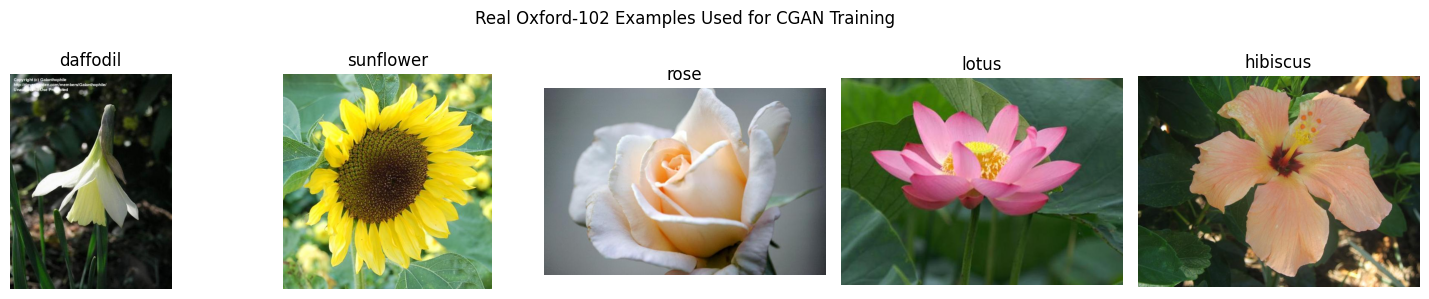

In [6]:
fig, axes = plt.subplots(1, len(SELECTED_CLASSES), figsize=(15, 3))
for ax, class_name in zip(axes, SELECTED_CLASSES):
    row = train_df[train_df["class_name"] == class_name].sample(1, random_state=SEED).iloc[0]
    img = Image.open(jpg_dir / row["filename"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(class_name)
    ax.axis("off")
plt.suptitle("Real Oxford-102 Examples Used for CGAN Training")
plt.tight_layout()
plt.show()


## 6. Image preprocessing and DataLoader

Images are center-cropped/resized to **64×64** and normalized to `[-1, 1]`, matching the Generator's `tanh` output.


In [7]:
IMAGE_SIZE = 64
BATCH_SIZE = 64

transform = transforms.Compose([
    transforms.Resize(72),
    transforms.CenterCrop(64),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

class FlowerCGANDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(self.image_dir / row["filename"]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        label = torch.tensor(int(row["cgan_label"]), dtype=torch.long)
        return image, label

dataset = FlowerCGANDataset(train_df, jpg_dir, transform)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True,
                        num_workers=2, pin_memory=(DEVICE.type == "cuda"), drop_last=False)

images, labels_batch = next(iter(dataloader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels_batch.shape)


Image batch shape: torch.Size([64, 3, 64, 64])
Label batch shape: torch.Size([64])


## 7. Why add Self-Attention?

Convolutional layers mainly learn from local neighborhoods. For image generation, however, distant regions can also be related—for example, petals on opposite sides of a flower should still form a coherent structure.

A **self-attention layer** lets the network compare features at different spatial positions and assign greater importance to relevant regions. This can help the GAN model more global structure instead of relying only on local convolutional patterns.

In this experiment, self-attention is inserted into both the Generator and the Discriminator.


In [8]:
LATENT_DIM = 100
NUM_CLASSES = len(SELECTED_CLASSES)
LABEL_EMBED_DIM = 32
CHANNELS = 3

class SelfAttention(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        reduced = max(1, in_channels // 8)
        self.query = nn.Conv2d(in_channels, reduced, kernel_size=1)
        self.key = nn.Conv2d(in_channels, reduced, kernel_size=1)
        self.value = nn.Conv2d(in_channels, in_channels, kernel_size=1)
        self.gamma = nn.Parameter(torch.zeros(1))
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        batch, channels, height, width = x.size()
        n = height * width

        q = self.query(x).view(batch, -1, n).permute(0, 2, 1)
        k = self.key(x).view(batch, -1, n)
        attention = self.softmax(torch.bmm(q, k))

        v = self.value(x).view(batch, channels, n)
        attended = torch.bmm(v, attention.permute(0, 2, 1))
        attended = attended.view(batch, channels, height, width)

        return self.gamma * attended + x

print("Self-Attention layer defined.")


Self-Attention layer defined.


## 8. Attention-CGAN architecture

### Attention Generator
The Generator receives random noise plus a learned flower-category embedding. After initial upsampling, a self-attention block is applied to intermediate feature maps before the image is completed.

### Attention Discriminator
The Discriminator receives the image plus a spatial representation of its category. A self-attention block is applied while the image is being downsampled, allowing the discriminator to evaluate relationships between distant visual regions.

The conditioning strategy remains consistent with Task 2, so the main experimental change is the introduction of attention.


In [9]:
class AttentionGenerator(nn.Module):
    def __init__(self, latent_dim=100, num_classes=5, embed_dim=32):
        super().__init__()
        self.label_embedding = nn.Embedding(num_classes, embed_dim)
        input_dim = latent_dim + embed_dim

        self.block1 = nn.Sequential(
            nn.ConvTranspose2d(input_dim, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True)
        )
        self.block2 = nn.Sequential(
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True)
        )
        self.block3 = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True)
        )

        # Self-attention at 16x16 resolution
        self.attention = SelfAttention(128)

        self.block4 = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True)
        )
        self.output = nn.Sequential(
            nn.ConvTranspose2d(64, CHANNELS, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, noise, labels):
        label_vec = self.label_embedding(labels)
        x = torch.cat([noise, label_vec], dim=1).unsqueeze(2).unsqueeze(3)
        x = self.block1(x)      # 4x4
        x = self.block2(x)      # 8x8
        x = self.block3(x)      # 16x16
        x = self.attention(x)   # attention
        x = self.block4(x)      # 32x32
        return self.output(x)   # 64x64


class AttentionDiscriminator(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.label_embedding = nn.Embedding(num_classes, IMAGE_SIZE * IMAGE_SIZE)

        self.block1 = nn.Sequential(
            nn.Conv2d(CHANNELS + 1, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True)
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True)
        )

        # Self-attention at 16x16 resolution
        self.attention = SelfAttention(128)

        self.block3 = nn.Sequential(
            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True)
        )
        self.block4 = nn.Sequential(
            nn.Conv2d(256, 512, 4, 2, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True)
        )
        self.output = nn.Conv2d(512, 1, 4, 1, 0, bias=False)

    def forward(self, images, labels):
        label_map = self.label_embedding(labels).view(
            labels.size(0), 1, IMAGE_SIZE, IMAGE_SIZE
        )
        x = torch.cat([images, label_map], dim=1)
        x = self.block1(x)       # 32x32
        x = self.block2(x)       # 16x16
        x = self.attention(x)    # attention
        x = self.block3(x)       # 8x8
        x = self.block4(x)       # 4x4
        return self.output(x).view(-1)


def weights_init(module):
    classname = module.__class__.__name__
    if "Conv" in classname:
        nn.init.normal_(module.weight.data, 0.0, 0.02)
    elif "BatchNorm" in classname:
        nn.init.normal_(module.weight.data, 1.0, 0.02)
        nn.init.constant_(module.bias.data, 0)
    elif "Embedding" in classname:
        nn.init.normal_(module.weight.data, 0.0, 0.02)


G_attn = AttentionGenerator(
    LATENT_DIM, NUM_CLASSES, LABEL_EMBED_DIM
).to(DEVICE)

D_attn = AttentionDiscriminator(NUM_CLASSES).to(DEVICE)

G_attn.apply(weights_init)
D_attn.apply(weights_init)

print(G_attn)
print(D_attn)
print("\nGenerator parameters:",
      f"{sum(p.numel() for p in G_attn.parameters()):,}")
print("Discriminator parameters:",
      f"{sum(p.numel() for p in D_attn.parameters()):,}")


AttentionGenerator(
  (label_embedding): Embedding(5, 32)
  (block1): Sequential(
    (0): ConvTranspose2d(132, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (block2): Sequential(
    (0): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (block3): Sequential(
    (0): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (attention): SelfAttention(
    (query): Conv2d(128, 16, kernel_size=(1, 1), stride=(1, 1))
    (key): Conv2d(128, 16, kernel_size=(1, 1), stride=(1, 1))
    (value): Conv2d(128, 128, kernel_size=(1, 1), stride=(1, 1))
    (

## 9. Verify model shapes before training

This quick test confirms that the Attention Generator creates 64×64 RGB images and that the Attention Discriminator returns one real/fake score per image.


In [10]:
test_noise = torch.randn(4, LATENT_DIM, device=DEVICE)
test_labels = torch.tensor([0, 1, 2, 3], device=DEVICE)

with torch.no_grad():
    test_fake = G_attn(test_noise, test_labels)
    test_scores = D_attn(test_fake, test_labels)

print("Generated image shape:", test_fake.shape)
print("Discriminator output shape:", test_scores.shape)

assert test_fake.shape == (4, 3, 64, 64)
assert test_scores.shape == (4,)
print("Shape check passed.")


Generated image shape: torch.Size([4, 3, 64, 64])
Discriminator output shape: torch.Size([4])
Shape check passed.


## 10. Training setup

The optimization settings are intentionally kept close to Task 2 so that the attention mechanism is the major architectural change.

`EPOCHS = 30` is the default. For a quick code test you may temporarily use 2–5 epochs, but for the final internship notebook run the full setting.


In [11]:
EPOCHS = 30
LR = 0.0002
BETA1 = 0.5

criterion = nn.BCEWithLogitsLoss()
optimizer_G = torch.optim.Adam(
    G_attn.parameters(), lr=LR, betas=(BETA1, 0.999)
)
optimizer_D = torch.optim.Adam(
    D_attn.parameters(), lr=LR, betas=(BETA1, 0.999)
)

fixed_noise = torch.randn(NUM_CLASSES * 4, LATENT_DIM, device=DEVICE)
fixed_labels = torch.arange(NUM_CLASSES, device=DEVICE).repeat_interleave(4)

os.makedirs("task5_samples", exist_ok=True)
os.makedirs("task5_models", exist_ok=True)

print("Training configuration ready.")


Training configuration ready.


## 11. Train the Attention-CGAN

The adversarial procedure remains the same as the Task 2 CGAN:
1. Train the discriminator on real image-label pairs.
2. Train it on generated image-label pairs.
3. Train the generator to make conditioned images that the discriminator classifies as real.

The difference is that both networks can now use self-attention while processing intermediate image features.


In [12]:
g_losses = []
d_losses = []

for epoch in range(EPOCHS):
    G_attn.train()
    D_attn.train()

    epoch_g = 0.0
    epoch_d = 0.0
    batches = 0

    progress = tqdm(
        dataloader,
        desc=f"Epoch {epoch+1}/{EPOCHS}",
        leave=False
    )

    for real_images, real_labels in progress:
        real_images = real_images.to(DEVICE, non_blocking=True)
        real_labels = real_labels.to(DEVICE, non_blocking=True)
        batch_size = real_images.size(0)

        real_targets = torch.ones(batch_size, device=DEVICE)
        fake_targets = torch.zeros(batch_size, device=DEVICE)

        # -------------------------
        # Train Discriminator
        # -------------------------
        optimizer_D.zero_grad()

        real_logits = D_attn(real_images, real_labels)
        loss_real = criterion(real_logits, real_targets)

        noise = torch.randn(batch_size, LATENT_DIM, device=DEVICE)
        fake_labels = torch.randint(
            0, NUM_CLASSES, (batch_size,), device=DEVICE
        )
        fake_images = G_attn(noise, fake_labels)

        fake_logits = D_attn(fake_images.detach(), fake_labels)
        loss_fake = criterion(fake_logits, fake_targets)

        d_loss = loss_real + loss_fake
        d_loss.backward()
        optimizer_D.step()

        # -------------------------
        # Train Generator
        # -------------------------
        optimizer_G.zero_grad()

        fake_logits_for_g = D_attn(fake_images, fake_labels)
        g_loss = criterion(fake_logits_for_g, real_targets)

        g_loss.backward()
        optimizer_G.step()

        epoch_d += d_loss.item()
        epoch_g += g_loss.item()
        batches += 1

        progress.set_postfix(
            D=f"{d_loss.item():.3f}",
            G=f"{g_loss.item():.3f}"
        )

    avg_d = epoch_d / batches
    avg_g = epoch_g / batches

    d_losses.append(avg_d)
    g_losses.append(avg_g)

    # Save fixed samples so progress can be inspected.
    if (epoch + 1) % 5 == 0 or epoch == 0 or epoch + 1 == EPOCHS:
        G_attn.eval()
        with torch.no_grad():
            fixed_fake = G_attn(fixed_noise, fixed_labels).cpu()

        save_image(
            fixed_fake,
            f"task5_samples/epoch_{epoch+1:03d}.png",
            nrow=4,
            normalize=True,
            value_range=(-1, 1)
        )

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"D Loss: {avg_d:.4f} | G Loss: {avg_g:.4f}"
    )

print("Attention-CGAN training complete.")


Epoch 1/30:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch [01/30] D Loss: 0.8610 | G Loss: 6.6706


Epoch 2/30:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch [02/30] D Loss: 0.5705 | G Loss: 10.4626


Epoch 3/30:   0%|          | 0/9 [00:00<?, ?it/s]

...

Epoch 29/30:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch [29/30] D Loss: 0.6460 | G Loss: 3.6034


Epoch 30/30:   0%|          | 0/9 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x780c0edf5c60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x780c0edf5c60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch [30/30] D Loss: 0.5810 | G Loss: 3.4204
Attention-CGAN training complete.


## 12. Plot Attention-CGAN training losses


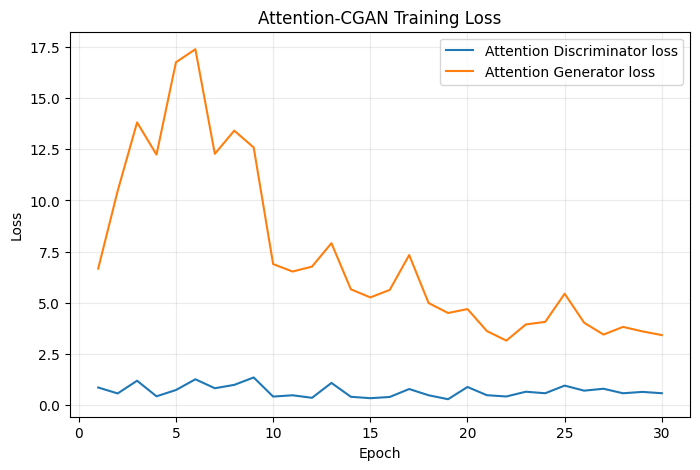

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(d_losses) + 1),
    d_losses,
    label="Attention Discriminator loss"
)
plt.plot(
    range(1, len(g_losses) + 1),
    g_losses,
    label="Attention Generator loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Attention-CGAN Training Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


## 13. Generate category-controlled samples

Each row represents one requested flower category. This demonstrates that the model remains conditional after introducing self-attention.


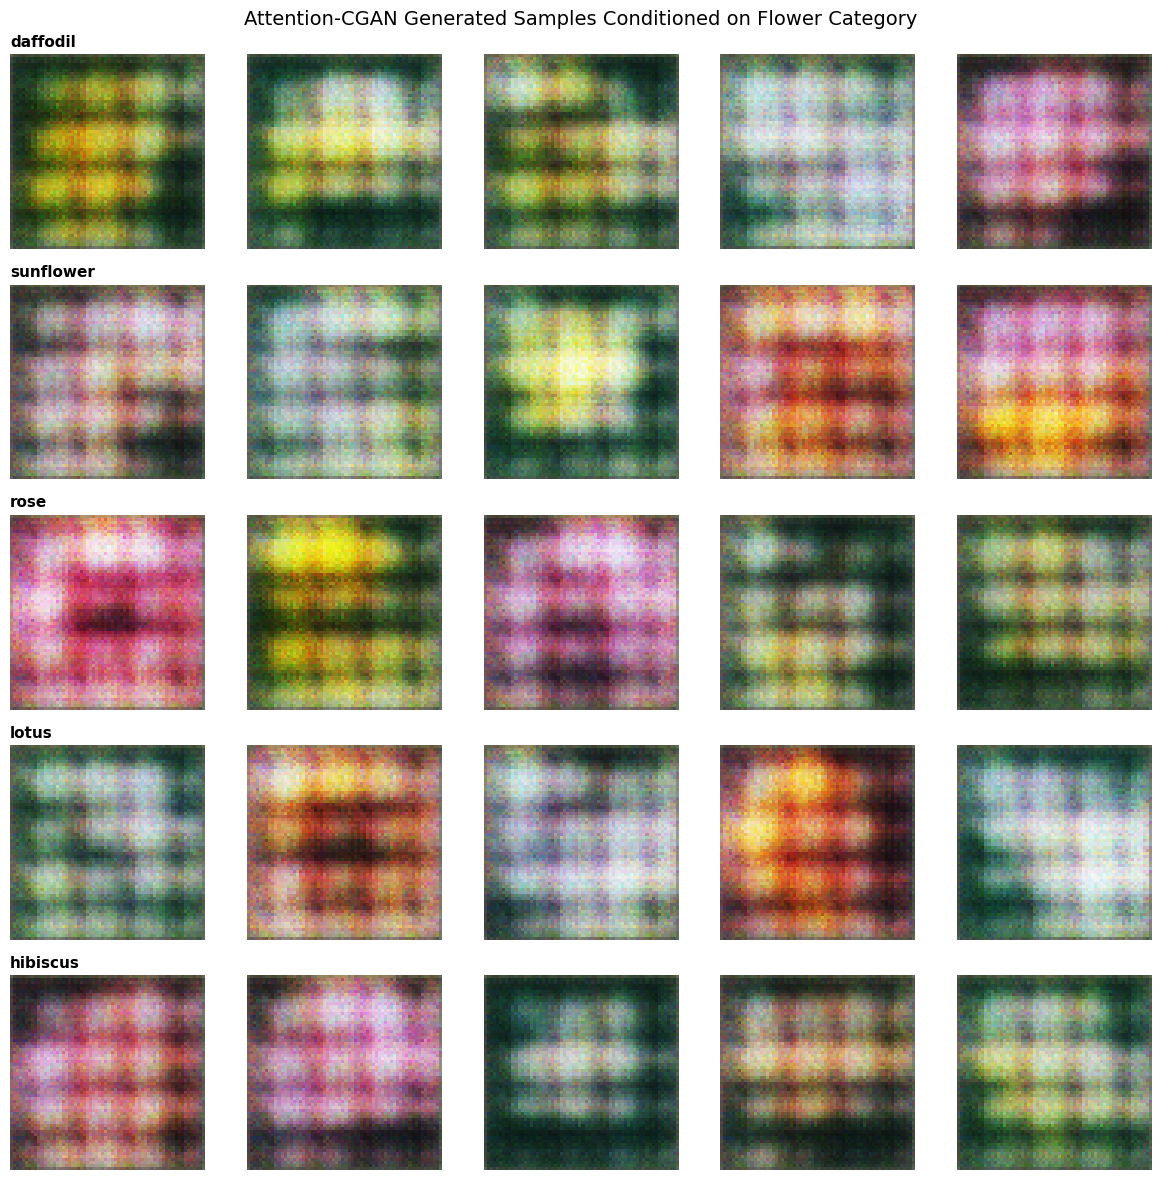

Saved: task5_attention_generated_flowers.png


In [14]:
G_attn.eval()
SAMPLES_PER_CLASS = 5

# Fixed seed makes this final display reproducible.
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

sample_noise = torch.randn(
    NUM_CLASSES * SAMPLES_PER_CLASS,
    LATENT_DIM,
    device=DEVICE
)
sample_labels = torch.arange(
    NUM_CLASSES, device=DEVICE
).repeat_interleave(SAMPLES_PER_CLASS)

with torch.no_grad():
    generated = G_attn(sample_noise, sample_labels).cpu()

generated_display = (generated + 1) / 2

fig, axes = plt.subplots(
    NUM_CLASSES,
    SAMPLES_PER_CLASS,
    figsize=(12, 12)
)

for r, class_name in enumerate(SELECTED_CLASSES):
    for c in range(SAMPLES_PER_CLASS):
        idx = r * SAMPLES_PER_CLASS + c
        img = generated_display[idx].permute(1, 2, 0).clamp(0, 1)
        axes[r, c].imshow(img)
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(
                class_name,
                loc="left",
                fontsize=11,
                fontweight="bold"
            )

plt.suptitle(
    "Attention-CGAN Generated Samples Conditioned on Flower Category",
    fontsize=14
)
plt.tight_layout()
plt.show()

save_image(
    generated,
    "task5_attention_generated_flowers.png",
    nrow=SAMPLES_PER_CLASS,
    normalize=True,
    value_range=(-1, 1)
)

print("Saved: task5_attention_generated_flowers.png")


## 14. Generate a flower from a chosen category

Change `REQUESTED_FLOWER` to any of the five categories and rerun this cell.


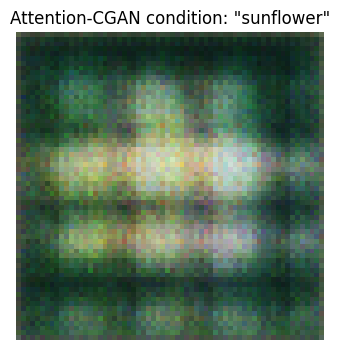

In [15]:
REQUESTED_FLOWER = "sunflower"
# Options: daffodil, sunflower, rose, lotus, hibiscus

assert REQUESTED_FLOWER in class_to_cgan, (
    f"Choose one of: {SELECTED_CLASSES}"
)

requested_label = torch.tensor(
    [class_to_cgan[REQUESTED_FLOWER]],
    device=DEVICE
)
noise = torch.randn(1, LATENT_DIM, device=DEVICE)

G_attn.eval()
with torch.no_grad():
    generated_one = G_attn(noise, requested_label).cpu()[0]

img = ((generated_one + 1) / 2).permute(1, 2, 0).clamp(0, 1)

plt.figure(figsize=(4, 4))
plt.imshow(img)
plt.title(f'Attention-CGAN condition: "{REQUESTED_FLOWER}"')
plt.axis("off")
plt.show()


## 15. Task 2 baseline vs Task 5 Attention-CGAN

The purpose of this task is to test an architectural improvement rather than claim that attention must always produce better images in a short training run.

| Feature | Task 2 CGAN | Task 5 Attention-CGAN |
|---|---|---|
| Dataset | Oxford-102 subset | Same Oxford-102 subset |
| Categories | 5 | Same 5 |
| Resolution | 64×64 | 64×64 |
| Conditioning | Class embeddings | Class embeddings |
| Generator | Convolutional upsampling | Convolutional upsampling + self-attention |
| Discriminator | Convolutional classifier | Convolutional classifier + self-attention |
| Long-range spatial modeling | Limited | Explicit self-attention |

Visual quality should be judged from the generated samples. GAN loss values alone are not a direct image-quality score.


In [16]:
comparison_df = pd.DataFrame({
    "Aspect": [
        "Dataset",
        "Classes",
        "Image size",
        "Conditioning",
        "Attention mechanism",
        "Main purpose"
    ],
    "Task 2 - Basic CGAN": [
        "Oxford-102 Flowers",
        "5 representative classes",
        "64x64",
        "Learned class embeddings",
        "No",
        "Baseline conditional generation"
    ],
    "Task 5 - Attention-CGAN": [
        "Oxford-102 Flowers",
        "Same 5 classes",
        "64x64",
        "Learned class embeddings",
        "Self-attention in G and D",
        "Model long-range spatial relationships"
    ]
})

display(comparison_df)


,Aspect,Task 2 - Basic CGAN,Task 5 - Attention-CGAN
0,Dataset,Oxford-102 Flowers,Oxford-102 Flowers
1,Classes,5 representative classes,Same 5 classes
2,Image size,64x64,64x64
3,Conditioning,Learned class embeddings,Learned class embeddings
4,Attention mechanism,No,Self-attention in G and D
5,Main purpose,Baseline conditional generation,Model long-range spatial relationships


## 16. Save trained models and experiment information


In [17]:
torch.save({
    "model_state_dict": G_attn.state_dict(),
    "selected_classes": SELECTED_CLASSES,
    "class_to_cgan": class_to_cgan,
    "latent_dim": LATENT_DIM,
    "label_embed_dim": LABEL_EMBED_DIM,
    "image_size": IMAGE_SIZE,
    "attention": "self-attention"
}, "task5_models/attention_cgan_generator.pth")

torch.save({
    "model_state_dict": D_attn.state_dict(),
    "selected_classes": SELECTED_CLASSES,
    "class_to_cgan": class_to_cgan,
    "image_size": IMAGE_SIZE,
    "attention": "self-attention"
}, "task5_models/attention_cgan_discriminator.pth")

history_df = pd.DataFrame({
    "epoch": range(1, len(g_losses) + 1),
    "generator_loss": g_losses,
    "discriminator_loss": d_losses
})
history_df.to_csv(
    "task5_attention_training_history.csv",
    index=False
)

comparison_df.to_csv(
    "task5_architecture_comparison.csv",
    index=False
)

print("Saved task5_models/attention_cgan_generator.pth")
print("Saved task5_models/attention_cgan_discriminator.pth")
print("Saved task5_attention_training_history.csv")
print("Saved task5_architecture_comparison.csv")


Saved task5_models/attention_cgan_generator.pth
Saved task5_models/attention_cgan_discriminator.pth
Saved task5_attention_training_history.csv
Saved task5_architecture_comparison.csv


## 17. Task 5 Summary and Conclusion

This experiment extends the Task 2 Conditional GAN by introducing **self-attention** into both adversarial networks. The flower category remains the conditional input, while attention allows intermediate feature maps to model relationships between spatially separated image regions.

Because GAN training is stochastic, a short experiment does not guarantee that every attention-generated sample will look better than every baseline sample. The important result of this task is the successful implementation and testing of an attention-enhanced conditional image-generation architecture on the same Oxford-102 project.


In [18]:
print("===== TASK 5 SUMMARY =====")
print("Dataset: Oxford-102 Flowers")
print(f"Full dataset classes: {len(FLOWER_CLASSES)}")
print(f"Attention-CGAN experiment classes: {NUM_CLASSES}")
print("Selected categories:", ", ".join(SELECTED_CLASSES))
print(f"Training images used: {len(train_df)}")
print(f"Image resolution: {IMAGE_SIZE}x{IMAGE_SIZE}")
print(f"Latent noise dimension: {LATENT_DIM}")
print("Attention strategy: Self-Attention")
print("Attention added to: Generator and Discriminator")
print(f"Training epochs completed: {len(g_losses)}")
print(f"Final Generator loss: {g_losses[-1]:.4f}")
print(f"Final Discriminator loss: {d_losses[-1]:.4f}")

print(
    "\nConclusion: Task 5 successfully extends the Task 2 CGAN with "
    "self-attention. The attention blocks allow the generator and discriminator "
    "to model relationships between distant spatial regions while retaining "
    "category-conditioned flower generation. Generated samples and training "
    "curves provide the experimental evidence for this architectural extension."
)


===== TASK 5 SUMMARY =====
Dataset: Oxford-102 Flowers
Full dataset classes: 102
Attention-CGAN experiment classes: 5
Selected categories: daffodil, sunflower, rose, lotus, hibiscus
Training images used: 559
Image resolution: 64x64
Latent noise dimension: 100
Attention strategy: Self-Attention
Attention added to: Generator and Discriminator
Training epochs completed: 30
Final Generator loss: 3.4204
Final Discriminator loss: 0.5810

Conclusion: Task 5 successfully extends the Task 2 CGAN with self-attention. The attention blocks allow the generator and discriminator to model relationships between distant spatial regions while retaining category-conditioned flower generation. Generated samples and training curves provide the experimental evidence for this architectural extension.


## Files to keep for the final internship submission

After all cells run successfully, keep/download:

- This executed `.ipynb` notebook with outputs visible
- `task5_attention_generated_flowers.png`
- `task5_attention_training_history.csv`
- `task5_architecture_comparison.csv`
- `task5_models/attention_cgan_generator.pth`
- `task5_models/attention_cgan_discriminator.pth`
- Representative images from the `task5_samples/` folder

For GitHub, the executed notebook, architecture comparison, training history, and representative generated images are especially useful. Large model-weight files can be omitted from GitHub if repository size becomes an issue.
